# One Declaration, Two Solvers: the Heated Rod by the Method of Lines

The [OCFESLV tutorial](OCFESLV_tutorial.ipynb) solved a nonlinear heat-conduction problem by
collocating **space and time together**: one large algebraic system over the whole space-time mesh,
or a sequence of them when marching. This tutorial takes the **same declaration** and hands it to
`DAESLV`, which treats it differently. It collocates **space only** -- the same finite elements and
nodes in $z$, by the same collocation machinery -- and integrates the resulting system of
differential-algebraic equations in time with SUNDIALS IDAS, an adaptive BDF integrator. This is
the **method of lines** (MoL).

Nothing in the model changes to make that happen. `DAESLV` recognises at setup that the model is
distributed in space, semi-discretises it, and from then on its working model *is* the semi-discrete
DAE: the solves, the sensitivities, the outputs and the statistics are its own, while the inputs,
the outputs and the gradients keep the names and layout of the PDE you declared. The two solvers
also share their option groups -- `options.INTERFACE` is the same path on both -- so moving a model
from one to the other is a matter of constructing a different solver.

What each solver discretises:

| | $z$ | $t$ |
|---|---|---|
| `OCFESLV` | collocation, finite elements | collocation, finite elements (a fixed order per element) |
| `DAESLV` | the same collocation | adaptive BDF steps; the time elements become **stages** |

The time mesh still matters to `DAESLV`: its element boundaries are where the integrator stops and
restarts, which is where a piecewise input changes its piece and where transitions happen.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from pymcpp import FFGraph, FFPartial, FFEval, FFIntegral, sqrt
from cronos import FFDom, FFModel, OCFESLV, DAESLV, CollocationOptions

## The model

The rod $z\in[0,1]$ conducts heat with a temperature-dependent diffusivity $D(u) = D_0(1+\beta u)$,
is held at $u=0$ at $z=0$ and heated at $z=1$ by a time-varying flux $q(t)$:
$$\begin{align*}
  \partial_t u &= \partial_z\big(D(u)\,\partial_z u\big), && 0<z<1,\\
  u(t,0) &= 0, \qquad D(u)\,\partial_z u\,(t,1) = q(t), \\
  u(0,z) &= a\,z, && \text{with } D_0(1+\beta a)\,a = q(0) = 1,
\end{align*}$$
so the initial profile is consistent with both boundary conditions. The heater follows a schedule
$q(t) = 0.625 + 0.375\cos 2\pi t$, collocated in time on three LGL nodes per element.

The declaration is written once, as a function of the solver, and used for both. Three outputs:
the end temperature $u(2,1)$; the space-time mean $\int\!\!\int u\,dz\,dt$; and the $L^2$ norm of the
end temperature over the horizon, $\big(\int_0^2 u(t,1)^2\,dt\big)^{1/2}$ -- a **nonlinear** function of an
integral, which both solvers take as an ordinary output.

In [2]:
D0, beta = 0.1, 1.0
a = (-1. + np.sqrt(1. + 4. * beta / D0)) / (2. * beta)   # D0 (1 + beta a) a = q(0) = 1
def heater(t):
    return 0.625 + 0.375 * np.cos(2. * np.pi * t)

def declare(S, G, NT=10, ORD_T=4, NZ=8):
    t, z = G.add_var("t"), G.add_var("z")
    u, q = G.add_var("u"), G.add_var("q")
    OpP, OpE, OpI = FFPartial(), FFEval(), FFIntegral()
    S.add_domain(t, FFDom(0., 2., NT, FFDom.LGR, ORD_T))
    S.add_domain(z, FFDom(0., 1., NZ, FFDom.LGL, 5))
    S.set_evolution_domain(t)
    S.add_state(u, [t, z], ref=0.)
    S.add_input(q, [t], ref=1., type=FFDom.LGL, n_node=3)
    D = D0 * (1. + beta * u)
    TI, ZI = FFDom.ALL - FFDom.LB, FFDom.ALL - FFDom.LB - FFDom.UB
    S.add_equation(OpP(u, t) - OpP(D * OpP(u, z), z), [t, z], [TI, ZI],                FFModel.EqnRole.INTERIOR)
    S.add_equation(u,                                  [t, z], [TI, FFDom.LB],          FFModel.EqnRole.BOUNDARY)
    S.add_equation(D * OpP(u, z) - q,                  [t, z], [TI, FFDom.UB],          FFModel.EqnRole.BOUNDARY)
    S.add_equation(u - a * z,                          [t, z], [FFDom.LB, FFDom.ALL],   FFModel.EqnRole.INITIAL)
    S.add_output(OpE(u, {t: 1, z: 1}, {t: 2., z: 1.}))                  # u(2,1)
    S.add_output(OpI(u, {t: 1, z: 1}))                                  # space-time mean
    S.add_output(sqrt(OpI(OpE(u, {z: 1}, {z: 1.}) ** 2, {t: 1})))      # L2 norm of the end temperature
    S.options.INTERFACE.IMPOSITION = CollocationOptions.IC_STRONG      # the same path on both solvers
    S.options.DISPLAY_LEVEL = 0
    return t, z, u, q

## Space-time collocation: the reference

First `OCFESLV`, monolithic, exactly as in its own tutorial. The inputs go **by name**: a dictionary
from the input to its values -- here a callable of the coordinates of each of its collocation nodes.

In [3]:
Go = FFGraph()
O = OCFESLV(Go)
t, z, u, q = declare(O, Go)
O.options.SOLVE.MARCHING = False
O.options.SOLVE.RES_TOL = 1e-10
O.setup()
t0 = time.perf_counter()
status = O.solve({q: lambda c: heater(c[t])})
cpu_o = time.perf_counter() - t0
F_o = list(O.val_function())
print(status, " (%.2f s)" % cpu_o)
print("u(2,1) = %.8f   mean = %.8f   ||u(.,1)|| = %.8f" % tuple(F_o))

STATUS.NORMAL  (0.82 s)
u(2,1) = 2.79055543   mean = 2.95779000   ||u(.,1)|| = 3.61856282


## The method of lines

The same declaration, on `DAESLV`. Its own options are the integrator's -- tolerances, and how many
points of the trajectory to record (`OUTPUT.RESRECORD`); the collocation options are the ones the
declaration already set.

`setup()` semi-discretises the rod: every node of $u$ becomes a state of a DAE, and so does every
node of the auxiliary flux $D(u)\,\partial_z u$ the collocation introduces for the flux-form operator.
A node held by a **boundary** condition rather than by the PDE is **algebraic**: $u(t,0)=0$ is an
algebraic equation, and so -- by default (`options.MOL.NEUMANN_NODE = NEUMANN_ALGEBRAIC`) -- is the
node at $z=1$, held by the flux condition. Its initial value is not imposed but solved for, starting
from the declared profile; that is one reason the initial profile should be consistent with the
boundary conditions, as $a\,z$ is here.

In [4]:
Gd = FFGraph()
S = DAESLV(Gd)
td, zd, ud, qd = declare(S, Gd)
S.options.SOLVE.RTOL = S.options.SOLVE.ATOL = 1e-10
S.options.SOLVE.VERBOSE = False
S.options.OUTPUT.RESRECORD = 20
S.setup()
nodes = S.semidiscrete_nodes(ud)
print("semi-discrete DAE: %d states; u has %d nodes, its z = 1 node is state %d"
      % (S.nx(), len(nodes), nodes[-1][0]))
print("Neumann node:", S.options.MOL.NEUMANN_NODE)

semi-discrete DAE: 84 states; u has 40 nodes, its z = 1 node is state 39
Neumann node: NeumannNode.NEUMANN_ALGEBRAIC


In [5]:
t0 = time.perf_counter()
status = S.solve({qd: lambda c: heater(c[td])})
cpu_d = time.perf_counter() - t0
F_d = list(S.val_function())
print(status, " (%.2f s, %d steps)" % (cpu_d, S.stats_solve.numSteps))
print("u(2,1) = %.8f   mean = %.8f   ||u(.,1)|| = %.8f" % tuple(F_d))
print("relative gap to OCFESLV:", ["%.1e" % (abs(x - y) / abs(y)) for x, y in zip(F_d, F_o)])

STATUS.NORMAL  (0.31 s, 132 steps)
u(2,1) = 2.79049623   mean = 2.95779948   ||u(.,1)|| = 3.61855088
relative gap to OCFESLV: ['2.1e-05', '3.2e-06', '3.3e-06']


The two agree to the accuracy of `OCFESLV`'s time collocation: `DAESLV`'s integrator runs at a
tolerance of $10^{-10}$, so the gap is almost entirely the time error of four Radau nodes per element.

## The temperature field

`DAESLV` records its trajectory at `RESRECORD` points per stage; `semidiscrete_nodes(u)` says which
column of the state holds each node of $u$, and where it sits. `OCFESLV`'s solution can be read at
any point with `eval_solution`. The profiles at four times, `OCFESLV` as lines and `DAESLV`'s nodes as
markers:

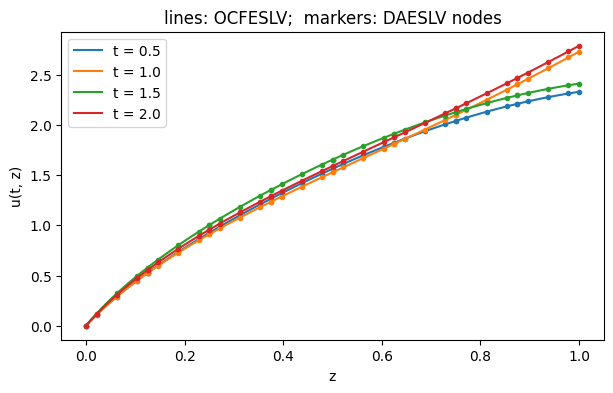

In [6]:
R = S.results_solve
cols = [c for c, _ in nodes]
zs = [coord[zd] for _, coord in nodes]
zz = np.linspace(0., 1., 101)
fig, ax = plt.subplots(figsize=(7, 4))
for tk, col in zip([0.5, 1.0, 1.5, 2.0], ["C0", "C1", "C2", "C3"]):
    k = int(np.argmin(np.abs(R.t - tk)))
    ax.plot(zz, [O.eval_solution(u, {t: tk, z: zi}) for zi in zz], color=col, label="t = %.1f" % tk)
    ax.plot(zs, R.x[k, cols], "o", color=col, ms=3)
ax.set_xlabel("z"); ax.set_ylabel("u(t, z)"); ax.legend(); ax.set_title("lines: OCFESLV;  markers: DAESLV nodes")
plt.show()

## Convergence in time

Refining `OCFESLV`'s time collocation closes the gap to the method of lines, which is
the expected behaviour of a collocation method on a smooth solution: the error falls by a factor at
every added node rather than by a power of the element size.

In [7]:
for order in [3, 4, 5, 6]:
    Gk = FFGraph(); Ok = OCFESLV(Gk); tk, zk, uk, qk = declare(Ok, Gk, ORD_T=order)
    Ok.options.SOLVE.MARCHING = False; Ok.options.SOLVE.RES_TOL = 1e-11
    Ok.setup(); Ok.solve({qk: lambda c: heater(c[tk])})
    gap = max(abs(x - y) / abs(y) for x, y in zip(Ok.val_function(), F_d))
    print("OCFESLV, %d Radau nodes per time element:  max relative gap to DAESLV %.2e" % (order, gap))

OCFESLV, 3 Radau nodes per time element:  max relative gap to DAESLV 3.49e-04


OCFESLV, 4 Radau nodes per time element:  max relative gap to DAESLV 2.12e-05


OCFESLV, 5 Radau nodes per time element:  max relative gap to DAESLV 3.62e-06


OCFESLV, 6 Radau nodes per time element:  max relative gap to DAESLV 1.58e-07


## Sensitivities with respect to the heater schedule

Both solvers give gradients **by name** with the same layout: `val_function_gradient()` has one row
per declared degree of freedom of the inputs -- here each collocation node of $q(t)$, in the order of
`input_dofs(q)` -- and one column per output. `DAESLV` offers forward and adjoint sensitivities; the
adjoint integrates one backward problem for all three outputs at once. The comparison is with
`OCFESLV` at six Radau nodes per element, the last solver of the convergence study.

In [8]:
heat_d = {qd: lambda c: heater(c[td])}
t0 = time.perf_counter(); S.solve_fsens(heat_d); Gf = np.array(S.val_function_gradient()); cpu_f = time.perf_counter() - t0
t0 = time.perf_counter(); S.solve_asens(heat_d); Ga = np.array(S.val_function_gradient()); cpu_a = time.perf_counter() - t0
Ok.solve_fsens({qk: lambda c: heater(c[tk])}); Go_ = np.array(Ok.val_function_gradient())   # OCFESLV at 6 Radau nodes, from above
print("gradient: %d rows (the DOFs of q) x %d columns (the outputs)" % Gf.shape)
print("DAESLV forward %.2f s, adjoint %.2f s;  max |adjoint - forward| = %.1e" % (cpu_f, cpu_a, np.abs(Ga - Gf).max()))
for j, name in enumerate(("u(2,1)", "mean", "||u(.,1)||")):
    print("%-11s max |DAESLV - OCFESLV| / max |OCFESLV| = %.1e" % (name, np.abs(Gf[:, j] - Go_[:, j]).max() / np.abs(Go_[:, j]).max()))

gradient: 30 rows (the DOFs of q) x 3 columns (the outputs)
DAESLV forward 1.78 s, adjoint 0.69 s;  max |adjoint - forward| = 8.8e-08
u(2,1)      max |DAESLV - OCFESLV| / max |OCFESLV| = 2.5e-02
mean        max |DAESLV - OCFESLV| / max |OCFESLV| = 1.5e-06
||u(.,1)||  max |DAESLV - OCFESLV| / max |OCFESLV| = 2.0e-03


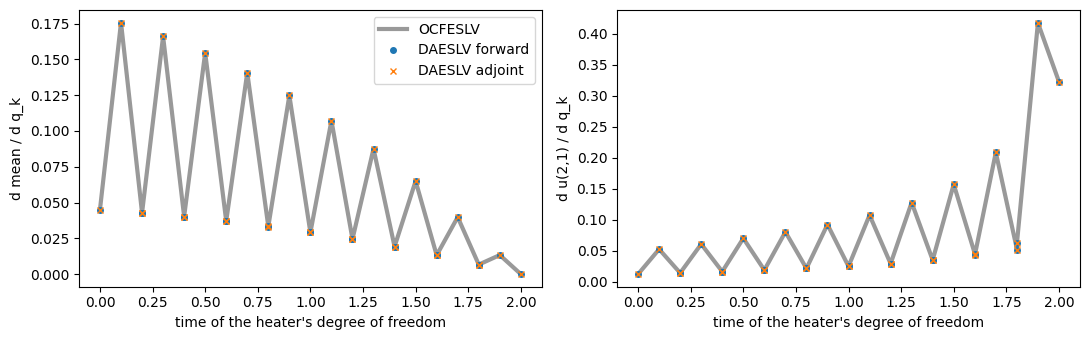

In [9]:
tq = [c[td] for c in S.input_coordinates(qd)]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, j, lab in zip(axs, (1, 0), ("d mean / d q_k", "d u(2,1) / d q_k")):
    ax.plot(tq, Go_[:, j], "-", color="0.6", lw=3, label="OCFESLV")
    ax.plot(tq, Gf[:, j], "o", ms=4, label="DAESLV forward")
    ax.plot(tq, Ga[:, j], "x", ms=5, label="DAESLV adjoint")
    ax.set_xlabel("time of the heater's degree of freedom"); ax.set_ylabel(lab)
axs[0].legend(); plt.tight_layout(); plt.show()

Each solver's gradient is the exact derivative of its own discrete solution -- a central
difference of either solver's values reproduces its own gradient -- and on the space-time **mean**
(left) the two agree to the time error. The end temperature (right) is the hardest output there is
to compare. Its sensitivity to the boundary flux at time $t$ behaves like the heat kernel at the
boundary, $\sim 1/\sqrt{2-t}$, singular at the end of the horizon; the integrator resolves it against
the spatial mesh, the collocation against its Radau nodes, and the two differ most in the last
element. The norm of the end temperature has that singularity at **every** instant, and its
gradients agree only to a few $10^{-3}$.

The saw-tooth is the heater's representation. It is declared **piecewise**, one quadratic per time
element with its own end values, so two degrees of freedom share each element boundary: the end of
one piece and the start of the next. Perturbing one alone makes the heater jump there; the integrator
sees the new piece from the stage's first instant, the Radau collocation only at its interior and
right-end nodes, and the two split the jump's effect between the pieces differently -- while agreeing
on its sum, which is what a change of the heater at that instant does.

## What to take away

* One declaration serves both solvers; the inputs, the outputs, the gradients and the collocation
  options have the same names and layout on both.
* `OCFESLV` collocates space and time: one nonlinear solve (or one per time element when marching),
  spectrally accurate in the time order, and the natural choice inside an optimisation that treats
  the whole trajectory as unknowns.
* `DAESLV` collocates space and integrates time: adaptive steps at a requested tolerance, and
  sensitivities by forward or adjoint integration; the natural choice for long horizons, stiff
  dynamics, or many outputs against few parameters.
* Algebraic nodes -- Dirichlet nodes, and by default Neumann nodes -- are solved for at $t_0$ from
  the declared profile, which should therefore be consistent with the boundary conditions.
* Gradients with respect to a piecewise input's degrees of freedom are exact for each solver's own
  discretisation; compare them across solvers on smooth outputs, and per instant at the pieces' ends.